# 06 — Model Experiments

**Module 02 evaluation.** Four model families compared on the same
chronological split, scored on metrics that matter for a rare, probabilistic
target.

The question this notebook answers:

> **Does any trained model beat the climatological baseline?**

Not "which model has the highest accuracy" — at a 2.92% base rate, predicting
*"no earthquake ever"* scores 97.08% accuracy and is worthless. We lead with
**PR-AUC** (discrimination under imbalance) and **Brier Skill Score**
(probabilistic skill versus the naive reference).

Artifacts are produced by:
```bash
seismo model train --all
seismo model evaluate --split val
seismo model evaluate --split test     # exactly once, after review
```

In [1]:
import glob
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from seismo.config import load_config

# Locate the project root so data paths resolve whether the notebook runs
# interactively or is executed by nbconvert (which may start in notebooks/).
# Imports above are unaffected — `seismo` is installed as a package.
for _candidate in [Path.cwd(), *Path.cwd().parents]:
    if (_candidate / "config" / "config.yaml").is_file():
        os.chdir(_candidate)
        break

sns.set_theme(style="whitegrid", font_scale=1.1)

NAVY = "#14263D"
ACCENT = "#2583A6"
LIGHT = "#E9EEF3"
ALERT = "#C0392B"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "text.color": NAVY,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
})

cfg = load_config()
ROOT = cfg.reports_dir / "model_metrics"
print(f"Report root: {ROOT}")

Report root: /home/abdel/Desktop/earthquake prediction model/reports/model_metrics


## 1. Collect evaluation reports

Each trained version writes `<split>.json` with the full metric bundle.
Only versions that have been evaluated appear here.

In [2]:
def collect(split: str) -> pd.DataFrame:
    rows = []
    for path in sorted(glob.glob(str(ROOT / "*" / "*" / f"{split}.json"))):
        m = json.loads(Path(path).read_text())
        version = Path(path).parent.name
        rows.append({
            "model": m.get("model"),
            "version": version,
            "split": m.get("split"),
            "n_rows": m.get("n_rows"),
            "positive_rate": m.get("positive_rate"),
            "threshold": m.get("threshold"),
            "pr_auc": m.get("pr_auc"),
            "roc_auc": m.get("roc_auc"),
            "brier": m.get("brier"),
            "brier_skill_score": m.get("brier_skill_score"),
            "ece": m.get("ece"),
            "f1": m.get("f1"),
            "precision": m.get("precision"),
            "recall": m.get("recall"),
        })
    return pd.DataFrame(rows)


val = collect("val")
assert not val.empty, (
    "No validation reports found — run `seismo model evaluate --split val` first."
)
val = val.sort_values("brier_skill_score", ascending=False).reset_index(drop=True)
display(val.style.format({
    "positive_rate": "{:.4f}", "threshold": "{:.4f}",
    "pr_auc": "{:.4f}", "roc_auc": "{:.4f}", "brier": "{:.5f}",
    "brier_skill_score": "{:.4f}", "ece": "{:.4f}",
    "f1": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}",
}, na_rep="—"))

,model,version,split,n_rows,positive_rate,threshold,pr_auc,roc_auc,brier,brier_skill_score,ece,f1,precision,recall
0,xgboost,v1-20261117T132818Z,val,552144,0.0318,0.1930,0.3571,0.8984,0.02465,0.0146,0.0021,0.3927,0.3805,0.4056
1,random_forest,v1-20261117T132653Z,val,552144,0.0318,0.1938,0.3502,0.8940,0.02479,0.0089,0.0014,0.3906,0.3812,0.4005
2,baseline_climatology,v1-20261117T115953Z,val,552144,0.0318,0.1595,0.3488,0.8959,0.02501,0.0000,0.0040,0.3919,0.3737,0.4121
3,logreg,v1-20261117T132459Z,val,552144,0.0318,0.1516,0.2878,0.8680,0.02632,-0.0522,0.0049,0.3363,0.3257,0.3476
4,baseline_poisson,v1-20261117T120004Z,val,552144,0.0318,0.0372,0.2535,0.8663,0.03031,-0.2118,0.0042,0.3377,0.2970,0.3914
5,baseline_global_rate,v1-20261117T115952Z,val,552144,0.0318,0.0283,0.0318,0.5000,0.03085,-0.2333,0.0035,0.0617,0.0318,1.0000


**How to read Brier Skill Score**

| BSS | Meaning |
|---|---|
| `> 0` | beats the climatological reference — the model added value |
| `= 0` | no better than counting history |
| `< 0` | **worse** than counting history — the model is harmful |

This is the honest yardstick: a Brier score in isolation means nothing
without knowing what the naive alternative achieves.

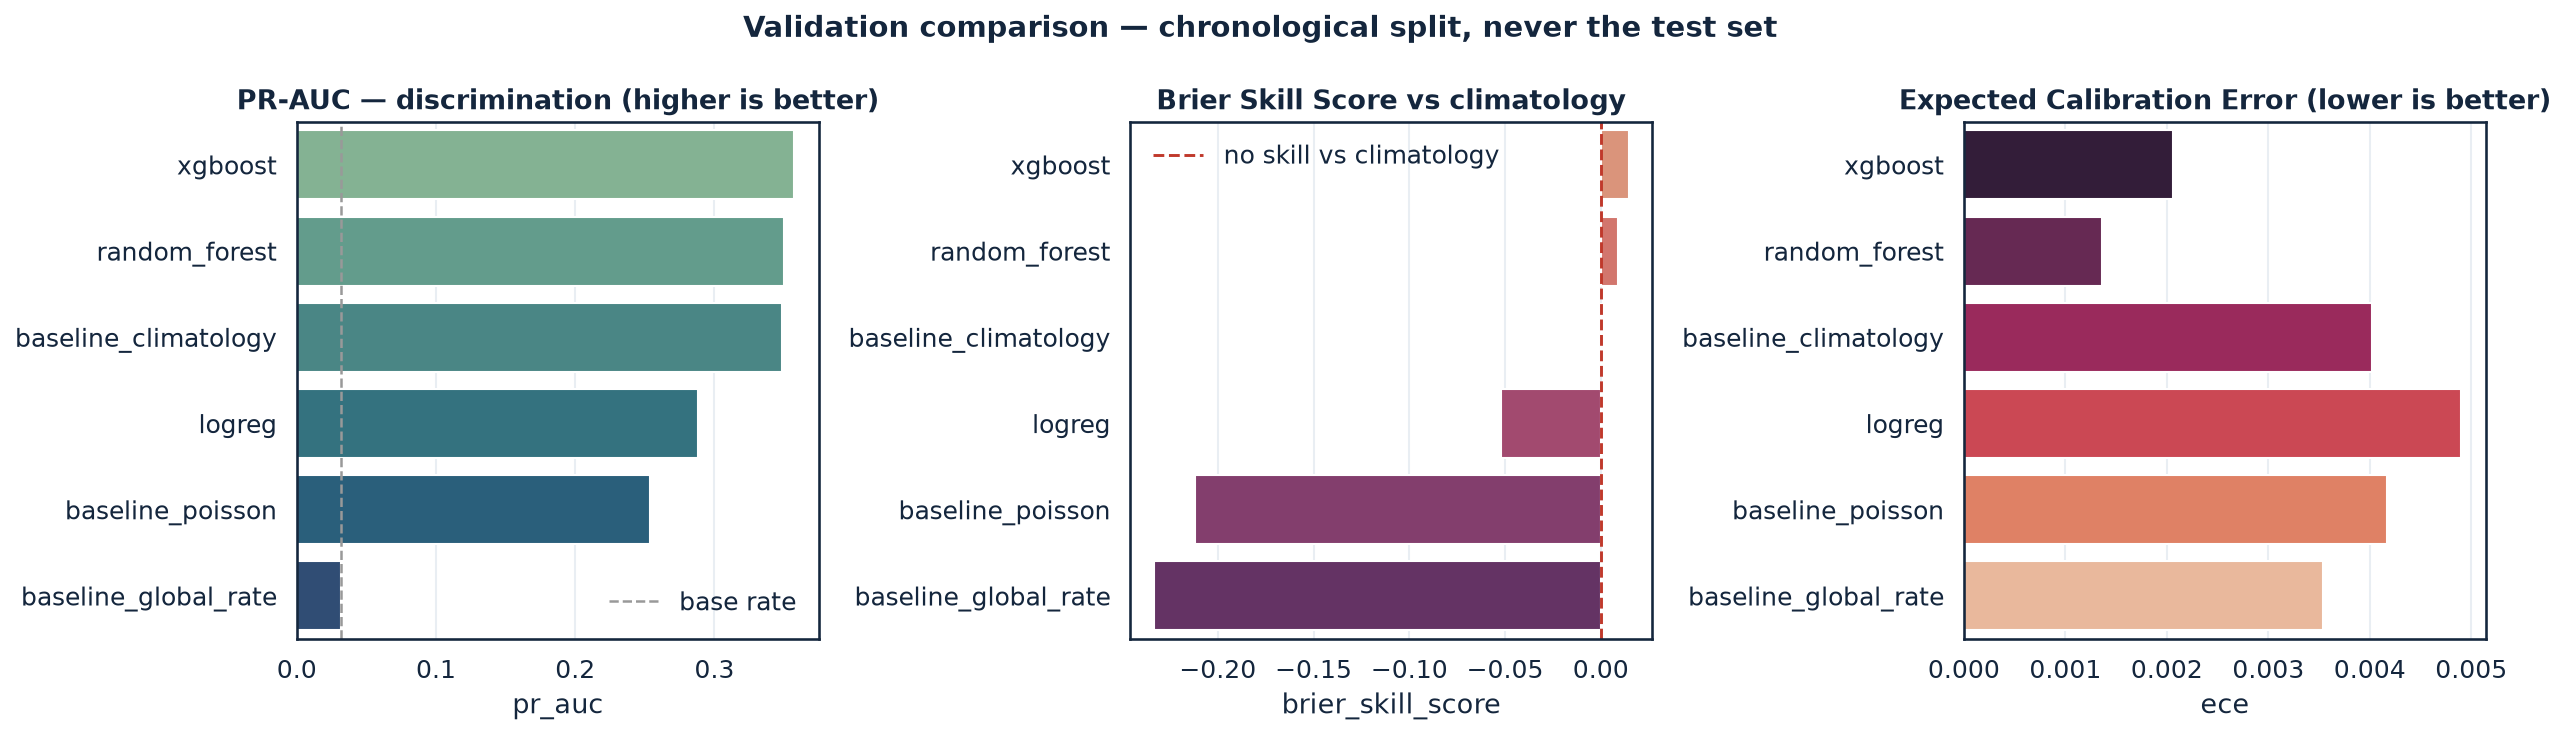

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

order = val.sort_values("pr_auc", ascending=False)["model"]

sns.barplot(data=val, y="model", x="pr_auc", hue="model",
            palette="crest", legend=False, ax=axes[0], order=order)
axes[0].axvline(val["positive_rate"].mean(), color="#999999", ls="--", lw=1.2,
                label="base rate")
axes[0].set_title("PR-AUC — discrimination (higher is better)")
axes[0].legend(frameon=False)

sns.barplot(data=val, y="model", x="brier_skill_score", hue="model",
            palette="flare", legend=False, ax=axes[1], order=order)
axes[1].axvline(0, color=ALERT, ls="--", lw=1.4, label="no skill vs climatology")
axes[1].set_title("Brier Skill Score vs climatology")
axes[1].legend(frameon=False)

sns.barplot(data=val, y="model", x="ece", hue="model",
            palette="rocket", legend=False, ax=axes[2], order=order)
axes[2].set_title("Expected Calibration Error (lower is better)")

for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=LIGHT)
    ax.set_ylabel("")

fig.suptitle("Validation comparison — chronological split, never the test set",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("reports/figures/model_validation_comparison.png", bbox_inches="tight")
plt.show()

## 2. Calibration

The defining test of a probabilistic model: **when it says 20%, does 20%
happen?** A model can rank well (high PR-AUC) and still be dangerously
miscalibrated — overconfident probabilities are how forecast products lose
trust.

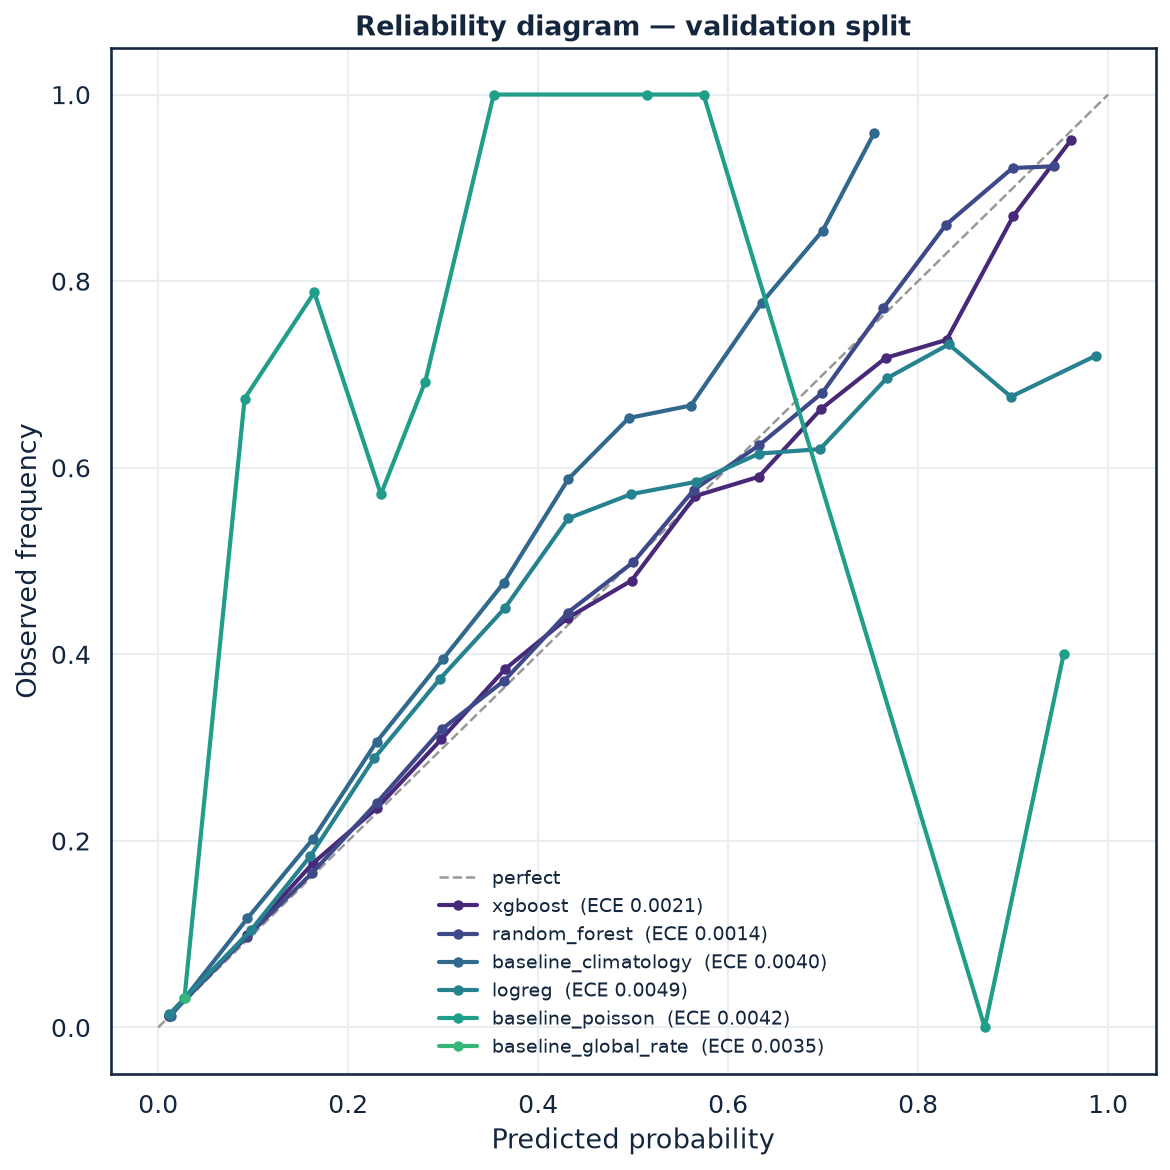

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([0, 1], [0, 1], ls="--", color="#999999", lw=1.2, label="perfect")

palette = sns.color_palette("viridis", n_colors=len(val) + 2)
for i, row in val.iterrows():
    paths = sorted(glob.glob(str(ROOT / row["model"] / row["version"] /
                                  "val_calibration.json")))
    if not paths:
        continue
    cal = pd.DataFrame(json.loads(Path(paths[0]).read_text()))
    ax.plot(cal["mean_predicted"], cal["observed_frequency"], "-o", lw=2, ms=4,
            color=palette[i], label=f"{row['model']}  (ECE {row['ece']:.4f})")

ax.set_xlabel("Predicted probability")
ax.set_ylabel("Observed frequency")
ax.set_title("Reliability diagram — validation split")
ax.legend(frameon=False, fontsize=9)
ax.grid(color=LIGHT)
fig.tight_layout()
fig.savefig("reports/figures/model_reliability.png", bbox_inches="tight")
plt.show()

## 3. Precision–Recall trade-off

Under a 2.92% base rate, precision and recall pull against each other. The
operating point (threshold) is chosen on **validation** and frozen before the
test split is ever scored.

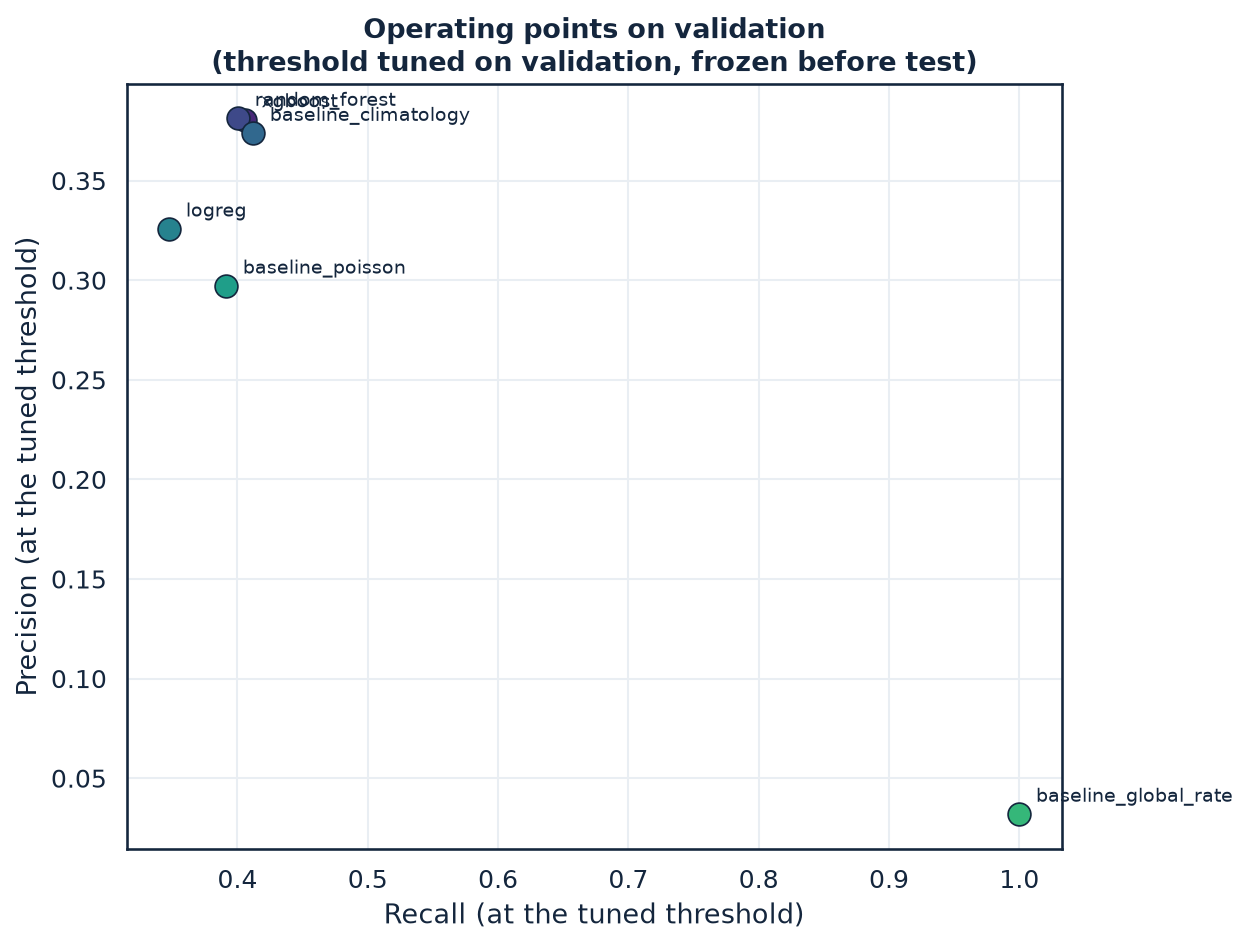

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for i, row in val.iterrows():
    # Operating point only: the full curve lives in the per-model report
    # figures, this view compares where each model was tuned to sit.
    ax.scatter(row["recall"], row["precision"], s=120, zorder=5,
               color=palette[i], edgecolor=NAVY, linewidth=0.8)
    ax.annotate(row["model"], (row["recall"], row["precision"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)

ax.set_xlabel("Recall (at the tuned threshold)")
ax.set_ylabel("Precision (at the tuned threshold)")
ax.set_title("Operating points on validation\n"
             "(threshold tuned on validation, frozen before test)")
ax.grid(color=LIGHT)
fig.tight_layout()
fig.savefig("reports/figures/model_operating_points.png", bbox_inches="tight")
plt.show()

## 4. Regional performance

The pooled metric can hide regional failure. The positive rate already spans
**0.62% – 11.98%** across named regions, so a model that performs well
globally may be systematically wrong somewhere specific.

Best model by Brier Skill Score: xgboost (BSS 0.0146)


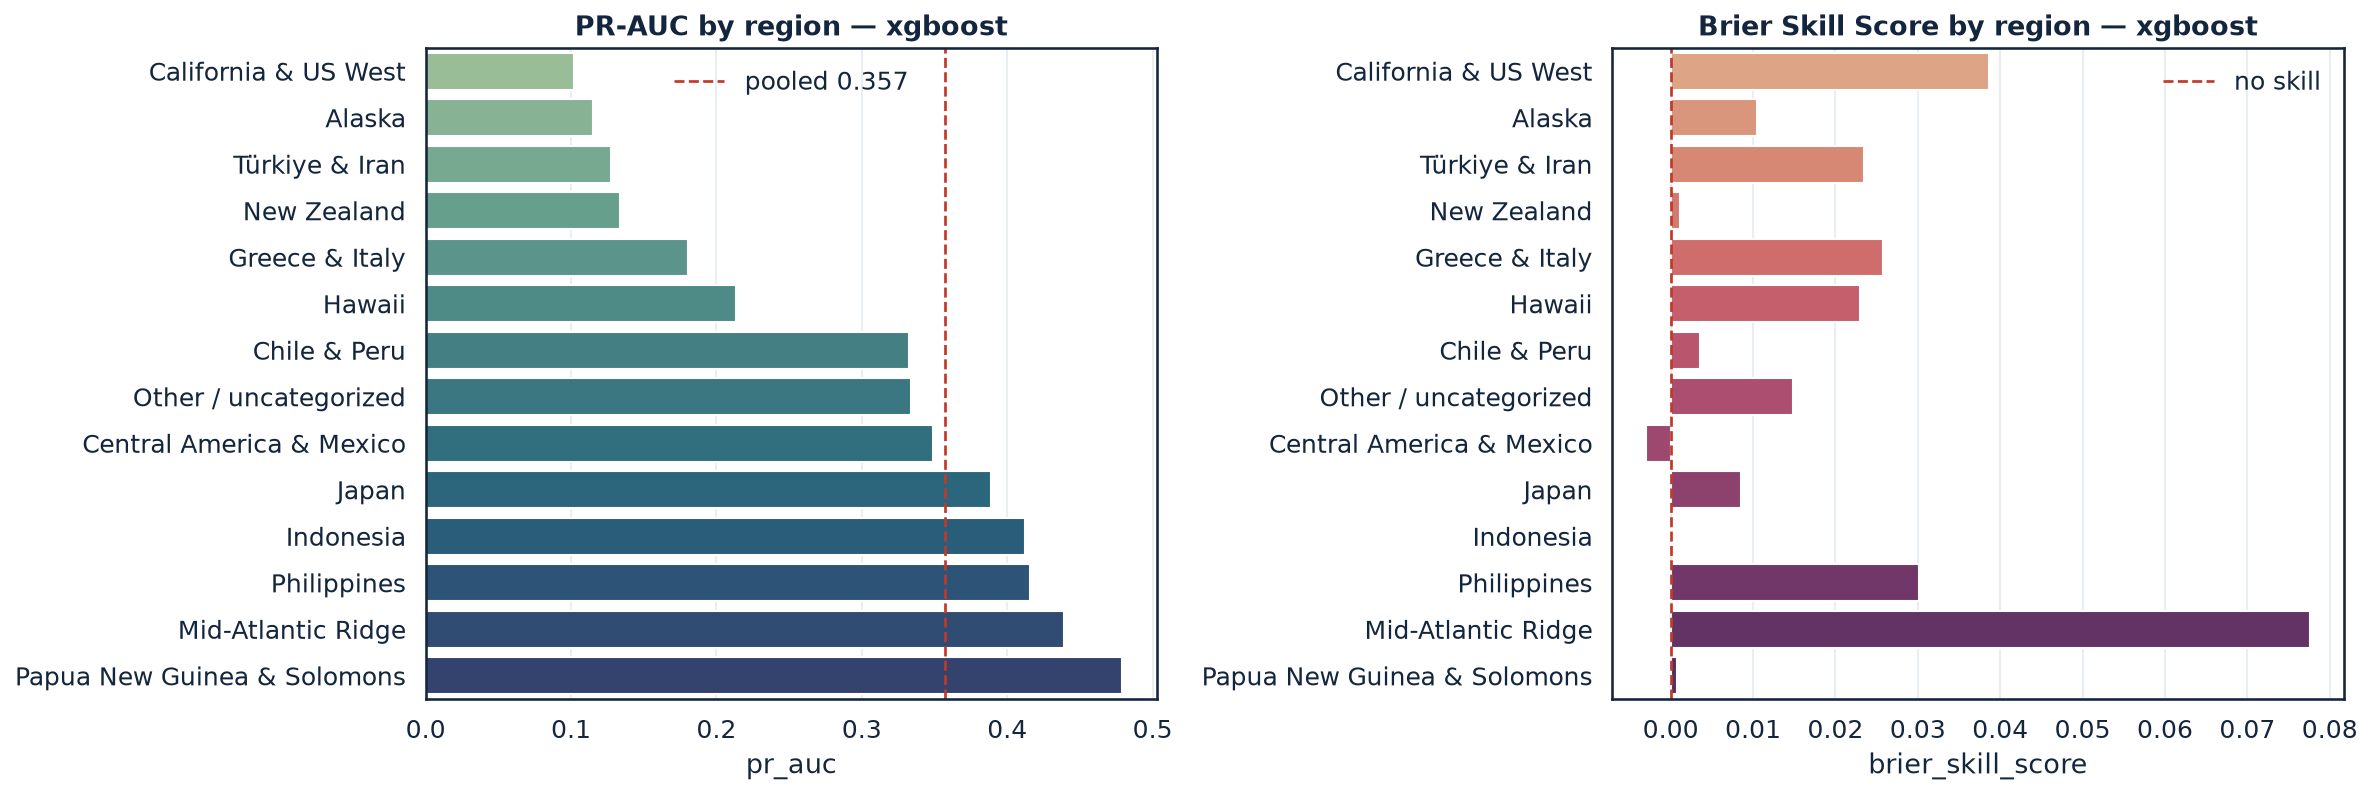

,region,n_rows,positive_rate,pr_auc,brier_skill_score,ece,reliable
10,California & US West,6096,0.007218,0.101705,0.038629,0.001289,True
1,Alaska,28848,0.007834,0.114808,0.010455,0.001924,True
4,Türkiye & Iran,15504,0.016318,0.127704,0.023522,0.001251,True
12,New Zealand,4608,0.027995,0.133501,0.001124,0.005681,True
6,Greece & Italy,12576,0.020038,0.180708,0.025823,0.006204,True
13,Hawaii,1104,0.015399,0.213536,0.023038,0.005594,True
5,Chile & Peru,13392,0.077584,0.332134,0.003613,0.004516,True
0,Other / uncategorized,389088,0.024457,0.334137,0.014866,0.001594,True
8,Central America & Mexico,8832,0.061368,0.348971,-0.003050,0.009192,True
7,Japan,11424,0.071429,0.389141,0.008485,0.006294,True


In [6]:
best = val.iloc[0]
print(f"Best model by Brier Skill Score: {best['model']} (BSS {best['brier_skill_score']:.4f})")

region_paths = sorted(glob.glob(str(ROOT / best["model"] / best["version"] /
                                    "val_by_region.json")))
region_df = pd.DataFrame(json.loads(Path(region_paths[0]).read_text()))
region_df = region_df[region_df["n_rows"] >= 500].sort_values("pr_auc")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.barplot(data=region_df, y="region", x="pr_auc", hue="region",
            palette="crest", legend=False, ax=axes[0])
axes[0].axvline(best["pr_auc"], color=ALERT, ls="--", lw=1.3,
                label=f"pooled {best['pr_auc']:.3f}")
axes[0].set_title(f"PR-AUC by region — {best['model']}")
axes[0].legend(frameon=False)

sns.barplot(data=region_df, y="region", x="brier_skill_score", hue="region",
            palette="flare", legend=False, ax=axes[1])
axes[1].axvline(0, color=ALERT, ls="--", lw=1.3, label="no skill")
axes[1].set_title(f"Brier Skill Score by region — {best['model']}")
axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=LIGHT)
    ax.set_ylabel("")

fig.tight_layout()
fig.savefig("reports/figures/model_regional_performance.png", bbox_inches="tight")
plt.show()

region_df[["region", "n_rows", "positive_rate", "pr_auc",
           "brier_skill_score", "ece", "reliable"]]

Regions marked `reliable = False` have fewer than 500 rows — their metrics
are shown for completeness but are **too noisy to claim anything from**.

In [7]:
print("Regions with negative skill (worse than counting history):")
worse = region_df[region_df["brier_skill_score"] < 0]
print(worse[["region", "n_rows", "brier_skill_score"]].to_string(index=False)
      if len(worse) else "  none")

Regions with negative skill (worse than counting history):
                  region  n_rows  brier_skill_score
Central America & Mexico    8832          -0.003050
               Indonesia   27648          -0.000025


## 5. Feature importance (SHAP)

Global attribution for the best model: which features move its predictions,
and by how much. SHAP values are *explanations of the model*, not causal
claims about earthquakes — trailing-window features are correlated by
construction.

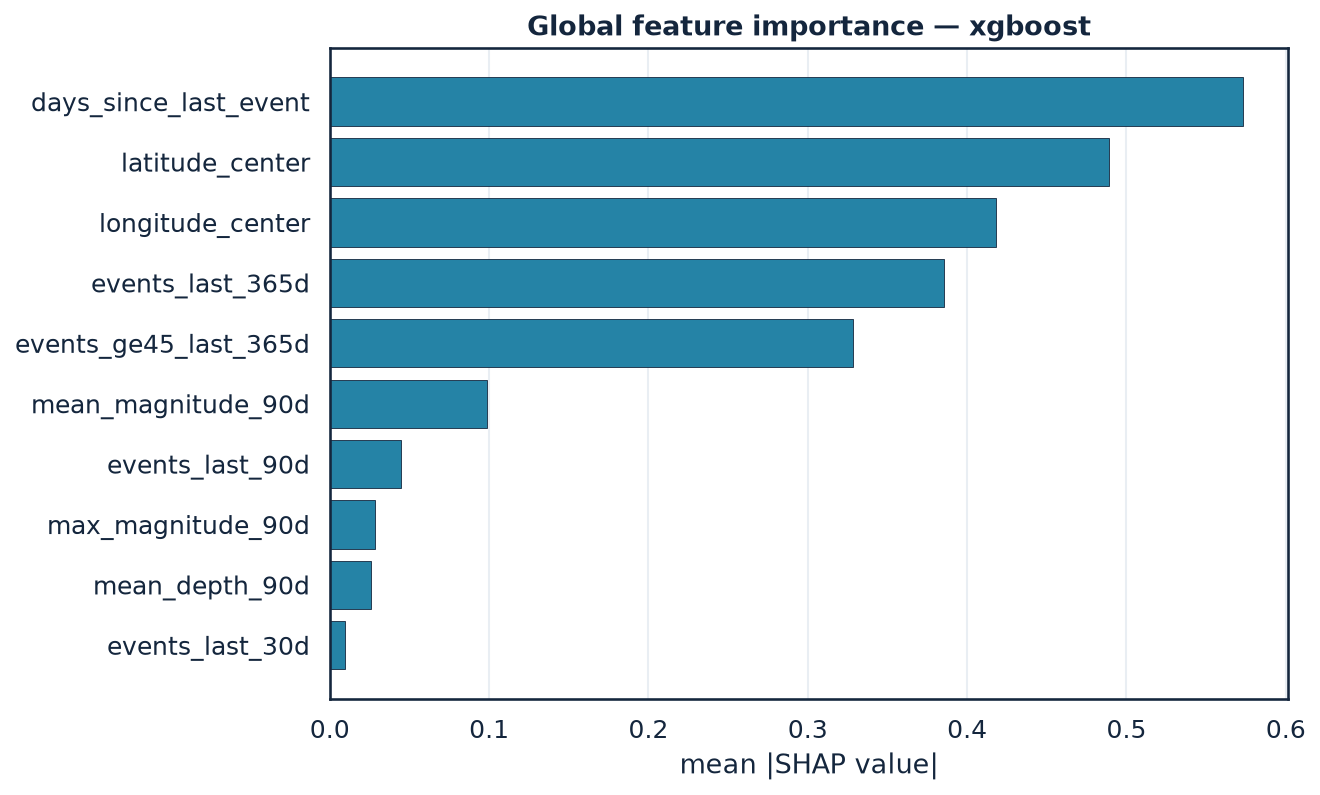

,feature,mean_abs_shap,share_of_total
0,days_since_last_event,0.572994,0.238531
1,latitude_center,0.489188,0.203643
2,longitude_center,0.418275,0.174123
3,events_last_365d,0.385613,0.160527
4,events_ge45_last_365d,0.328190,0.136622
5,mean_magnitude_90d,0.098897,0.041170
6,events_last_90d,0.044864,0.018676
7,max_magnitude_90d,0.028389,0.011818
8,mean_depth_90d,0.026021,0.010832
9,events_last_30d,0.009747,0.004058


In [8]:
shap_paths = sorted(glob.glob(str(ROOT / best["model"] / best["version"] /
                                 "val_shap_importance.json")))
importance = []
for path in shap_paths:
    importance = json.loads(Path(path).read_text())

if not importance:
    # SHAP is written into the metrics bundle for ML models.
    metrics_paths = sorted(glob.glob(str(ROOT / best["model"] / best["version"] /
                                        "val.json")))
    if metrics_paths:
        importance = json.loads(Path(metrics_paths[0]).read_text()).get(
            "shap_top_features", [])

if importance:
    imp = pd.DataFrame(importance)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    top = imp.head(12).iloc[::-1]
    ax.barh(top["feature"], top["mean_abs_shap"], color=ACCENT,
            edgecolor=NAVY, linewidth=0.4)
    ax.set_xlabel("mean |SHAP value|")
    ax.set_title(f"Global feature importance — {best['model']}")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=LIGHT)
    fig.tight_layout()
    fig.savefig("reports/figures/model_shap_importance.png", bbox_inches="tight")
    plt.show()
    display(imp)
else:
    print("No SHAP report found (baselines do not produce SHAP values).")

## 6. The test split — touched exactly once

Everything above used **validation**. The test split (2023 → 2026) has not
been used for threshold tuning, model selection, or early stopping.

Run it once, deliberately, after reviewing the validation evidence:

```bash
seismo model evaluate --split test
```

Reusing test for further tuning would destroy the holdout — that is why the
threshold is stored from validation and reused, never re-derived.

In [9]:
test = collect("test")
if test.empty:
    print("Test reports not generated yet — that is the correct state until "
          "`seismo model evaluate --split test` has been run once.")
else:
    test = test.sort_values("brier_skill_score", ascending=False)
    print("=== TEST SPLIT (holdout, scored once) ===")
    display(test[["model", "split", "n_rows", "pr_auc", "brier",
                  "brier_skill_score", "ece", "f1", "threshold"]].style.format({
        "pr_auc": "{:.4f}", "brier": "{:.5f}",
        "brier_skill_score": "{:.4f}", "ece": "{:.4f}",
        "f1": "{:.4f}", "threshold": "{:.4f}",
    }, na_rep="—"))

=== TEST SPLIT (holdout, scored once) ===


,model,split,n_rows,pr_auc,brier,brier_skill_score,ece,f1,threshold
5,xgboost,test,529138,0.3519,0.02379,0.0189,0.0010,0.3957,0.1930
4,random_forest,test,529138,0.3483,0.02387,0.0158,0.0006,0.3929,0.1938
0,baseline_climatology,test,529138,0.3351,0.02425,0.0000,0.0040,0.3878,0.1595
3,logreg,test,529138,0.2815,0.02544,-0.0491,0.0037,0.3376,0.1516
2,baseline_poisson,test,529138,0.2485,0.02919,-0.2036,0.0030,0.3380,0.0372
1,baseline_global_rate,test,529138,0.0307,0.02973,-0.2261,0.0024,0.0595,0.0283


## 7. Conclusions

The decision rule for promotion:

1. **Brier Skill Score > 0** on validation — otherwise counting history wins
   and the model should not ship.
2. **Calibration acceptable** — ECE small enough that stated probabilities
   can be trusted at face value.
3. **No region with materially negative skill** among well-sampled regions.
4. **Promotion is a human act**: `seismo model promote --reviewed-by <name>`
   requires a named reviewer and a prior evaluation.

In [10]:
registry = json.loads((cfg.models_dir / "registry.json").read_text()) \
    if (cfg.models_dir / "registry.json").is_file() else {"production": {}}

summary = {
    "models_evaluated_val": int(len(val)),
    "best_model": str(best["model"]),
    "best_pr_auc": round(float(best["pr_auc"]), 4),
    "best_brier_skill_score": round(float(best["brier_skill_score"]), 4),
    "best_ece": round(float(best["ece"]), 4),
    "models_beating_baseline": val.loc[
        val["brier_skill_score"] > 0, "model"].tolist(),
    "production_registry": registry.get("production", {}),
    "test_scored": bool(len(test)),
}
summary

{'models_evaluated_val': 6,
 'best_model': 'xgboost',
 'best_pr_auc': 0.3571,
 'best_brier_skill_score': 0.0146,
 'best_ece': 0.0021,
 'models_beating_baseline': ['xgboost', 'random_forest'],
 'production_registry': {},
 'test_scored': True}